In [67]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [68]:
df = pd.read_csv("netflix_titles.csv")
df.head()

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,NaN,NaN,NaN,"September 24, 2021",2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...


In [69]:
## Number of rows and columns in the dataset
print(f"Number of rows, columns in the dataset: {df.shape}")

# List of columns in the dataset
print(f"List of columns in the dataset: {df.columns.to_list()}")

# Information about the dataset
df.info()

# Number of missing values in each column
print(f"Sum of missing values in each column: {df.isnull().sum()}")

Number of rows, columns in the dataset: (8807, 12)
List of columns in the dataset: ['show_id', 'type', 'title', 'director', 'cast', 'country', 'date_added', 'release_year', 'rating', 'duration', 'listed_in', 'description']
<class 'pandas.DataFrame'>
RangeIndex: 8807 entries, 0 to 8806
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   show_id       8807 non-null   str  
 1   type          8807 non-null   str  
 2   title         8807 non-null   str  
 3   director      6173 non-null   str  
 4   cast          7982 non-null   str  
 5   country       7976 non-null   str  
 6   date_added    8797 non-null   str  
 7   release_year  8807 non-null   int64
 8   rating        8803 non-null   str  
 9   duration      8804 non-null   str  
 10  listed_in     8807 non-null   str  
 11  description   8807 non-null   str  
dtypes: int64(1), str(11)
memory usage: 825.8 KB
Sum of missing values in each column: show_id            0

In [70]:
## Checking for duplicated rows
print(f"Are there duplicate rows: {df.duplicated().any()}")

## Number of duplicated rows
print(f"Number of duplicated rows: {df.duplicated().sum()}")

## Removing duplicated rows
df = df.drop_duplicates()

Are there duplicate rows: False
Number of duplicated rows: 0


In [71]:
## Counting number of Movies and TV shows
print(df["type"].value_counts())

## Identifying Country with the most netflix title
print(f"Country with the most Netflix titles: {df['country'].value_counts().idxmax()}")

## Identifying year with highest number of release
print(f"Year with the highest number of release title: {df.groupby('release_year')['title'].count().idxmax()}")

## Most occuring rating
print(f"Most occuring rating: {df['rating'].value_counts().idxmax()}")

## Most recent movies
print("Top ten most recent movies:\n", df[df['type']=='Movie'].sort_values(by='date_added',ascending=False).head(10))


type
Movie      6131
TV Show    2676
Name: count, dtype: int64
Country with the most Netflix titles: United States
Year with the highest number of release title: 2018
Most occuring rating: TV-MA
Top ten most recent movies:
      show_id   type                                     title  \
88       s89  Movie  Blood Brothers: Malcolm X & Muhammad Ali   
90       s91  Movie                            Paradise Hills   
91       s92  Movie                The Women and the Murderer   
2034   s2035  Movie                      So Much Love to Give   
2030   s2031  Movie                                     Cargo   
2031   s2032  Movie                                    Cuties   
2035   s2036  Movie                        The Social Dilemma   
7596   s7597  Movie   Norm of the North: King Sized Adventure   
5798   s5799  Movie                Jandino: Whatever it Takes   
93       s94  Movie                                      JJ+E   

                                director  \
88              

In [72]:
df[df["date_added"].isna()]

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
6066,s6067,TV Show,A Young Doctor's Notebook and Other Stories,NaN,"Daniel Radcliffe, Jon Hamm, Adam Godley, Chris...",United Kingdom,NaN,2013,TV-MA,2 Seasons,"British TV Shows, TV Comedies, TV Dramas","Set during the Russian Revolution, this comic ..."
6174,s6175,TV Show,Anthony Bourdain: Parts Unknown,NaN,Anthony Bourdain,United States,NaN,2018,TV-PG,5 Seasons,Docuseries,This CNN original series has chef Anthony Bour...
6795,s6796,TV Show,Frasier,NaN,"Kelsey Grammer, Jane Leeves, David Hyde Pierce...",United States,NaN,2003,TV-PG,11 Seasons,"Classic & Cult TV, TV Comedies",Frasier Crane is a snooty but lovable Seattle ...
6806,s6807,TV Show,Friends,NaN,"Jennifer Aniston, Courteney Cox, Lisa Kudrow, ...",United States,NaN,2003,TV-14,10 Seasons,"Classic & Cult TV, TV Comedies",This hit sitcom follows the merry misadventure...
6901,s6902,TV Show,Gunslinger Girl,NaN,"Yuuka Nanri, Kanako Mitsuhashi, Eri Sendai, Am...",Japan,NaN,2008,TV-14,2 Seasons,"Anime Series, Crime TV Shows","On the surface, the Social Welfare Agency appe..."
7196,s7197,TV Show,Kikoriki,NaN,Igor Dmitriev,NaN,NaN,2010,TV-Y,2 Seasons,Kids' TV,A wacky rabbit and his gang of animal pals hav...
7254,s7255,TV Show,La Familia P. Luche,NaN,"Eugenio Derbez, Consuelo Duval, Luis Manuel Áv...",United States,NaN,2012,TV-14,3 Seasons,"International TV Shows, Spanish-Language TV Sh...","This irreverent sitcom featues Ludovico, Feder..."
7406,s7407,TV Show,Maron,NaN,"Marc Maron, Judd Hirsch, Josh Brener, Nora Zeh...",United States,NaN,2016,TV-MA,4 Seasons,TV Comedies,"Marc Maron stars as Marc Maron, who interviews..."
7847,s7848,TV Show,Red vs. Blue,NaN,"Burnie Burns, Jason Saldaña, Gustavo Sorola, G...",United States,NaN,2015,NR,13 Seasons,"TV Action & Adventure, TV Comedies, TV Sci-Fi ...","This parody of first-person shooter games, mil..."
8182,s8183,TV Show,The Adventures of Figaro Pho,NaN,"Luke Jurevicius, Craig Behenna, Charlotte Haml...",Australia,NaN,2015,TV-Y7,2 Seasons,"Kids' TV, TV Comedies","Imagine your worst fears, then multiply them: ..."


In [73]:
## Handling missing values
df.head()
df["director"]=df["director"].fillna("Unknown")
df["cast"]=df["cast"].fillna("Unknown")
df["country"]=df["country"].fillna("Unknown")
df["rating"]=df["rating"].fillna("Not Rated")
df=df.dropna(subset="date_added")
df.head()

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,Unknown,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,Unknown,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",Unknown,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,Unknown,Unknown,Unknown,"September 24, 2021",2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,Unknown,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...


In [74]:
## Director with the most Netflix titles
print(f"Director with the most Netflix titles: {df[df['director']!='Unknown']['director'].value_counts().idxmax()}")

Director with the most Netflix titles: Rajiv Chilaka


In [75]:
## Actor/Actress that appears the most
print(f"Most frequent Actor/Actress: {df["cast"].str.split(",").explode()[df['cast'].str.split(",").explode()!='Unknown'].value_counts().idxmax()}")


Most frequent Actor/Actress:  Anupam Kher


In [76]:
## Most frequent Rating
print(f"Most frequent rating: {df['rating'].value_counts().idxmax()}")

Most frequent rating: TV-MA


In [77]:
## Contry with the most Most Movies
print(f"Country with the most movies: {df[df["type"]=="Movie"][df["country"]!="Unknown"]["country"].value_counts().idxmax()}")

Country with the most movies: United States


C:\Users\Giwa\AppData\Local\Temp\ipykernel_3216\1639016799.py:2: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  print(f"Country with the most movies: {df[df["type"]=="Movie"][df["country"]!="Unknown"]["country"].value_counts().idxmax()}")


In [78]:
## Contry with the most Most TV Shows
print(f"Country with the most TV shows: {df[df["type"]=="TV Show"][df["country"]!="Unknown"]["country"].value_counts().idxmax()}")

Country with the most TV shows: United States


C:\Users\Giwa\AppData\Local\Temp\ipykernel_3216\3231333450.py:2: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  print(f"Country with the most TV shows: {df[df["type"]=="TV Show"][df["country"]!="Unknown"]["country"].value_counts().idxmax()}")


In [79]:
## Month with most added title
df["date_added"] = pd.to_datetime(df['date_added'], format="mixed")
print(f"Month with the highest number of titles added: {df["date_added"].dt.month_name().value_counts().idxmax()}")

Month with the highest number of titles added: July


In [80]:
## Year with most added title
print(f"Year with most added title: {df['date_added'].dt.year.value_counts().idxmax()}")

Year with most added title: 2019


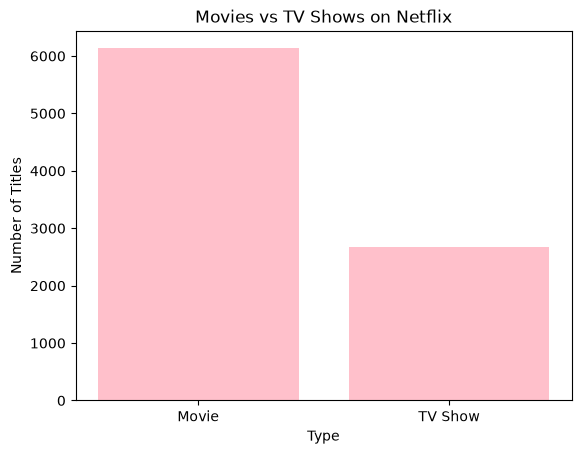

In [81]:
## Bar chart of Movies Vs TV Shows
plt.bar(df["type"].value_counts().index, df["type"].value_counts().values,color="pink")
plt.title("Movies vs TV Shows on Netflix")
plt.xlabel("Type")
plt.ylabel("Number of Titles")
plt.show()

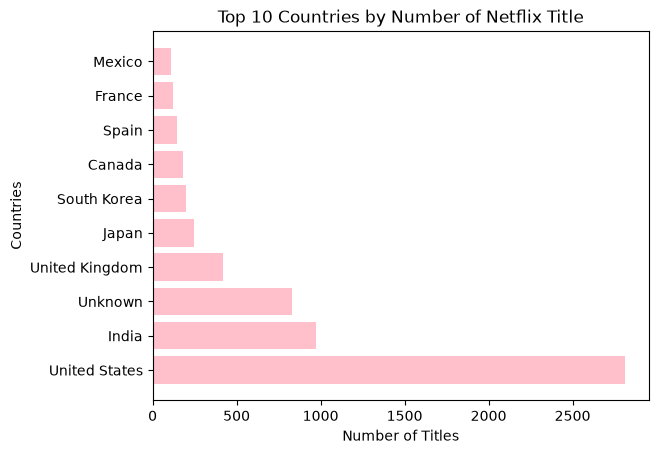

In [82]:
## Horizontal Bar Chart of Top ten Countries
plt.barh(df["country"].value_counts().head(10).index,df["country"].value_counts().head(10).values,color="pink")
plt.title("Top 10 Countries by Number of Netflix Title")
plt.xlabel("Number of Titles")
plt.ylabel("Countries")
plt.show()

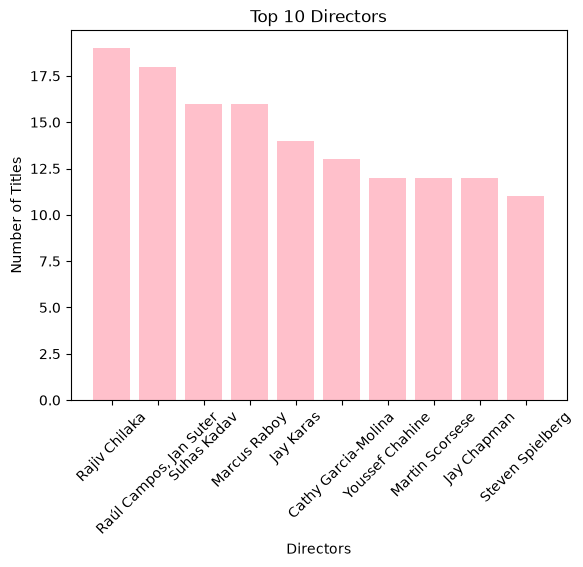

In [83]:
## Bar Chart of Top ten Directors
plt.bar(df[df["director"]!="Unknown"]["director"].value_counts().head(10).index,df[df["director"]!="Unknown"]["director"].value_counts().head(10).values,color="pink")
plt.title("Top 10 Directors")
plt.xlabel("Directors")
plt.ylabel("Number of Titles")
plt.xticks(rotation=45)
plt.show()

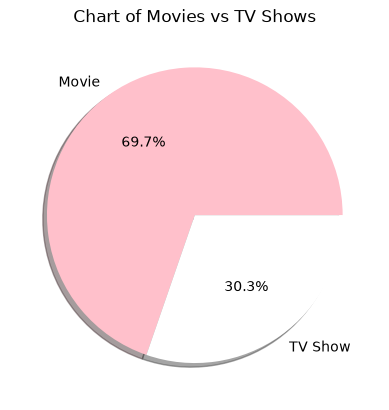

In [84]:
## Pie Chart of Movies VS TV Shows
plt.pie(df["type"].value_counts(),labels=df["type"].value_counts().index,autopct="%1.1f%%",shadow=True,colors=["pink","white"])
plt.title("Chart of Movies vs TV Shows")
plt.show()

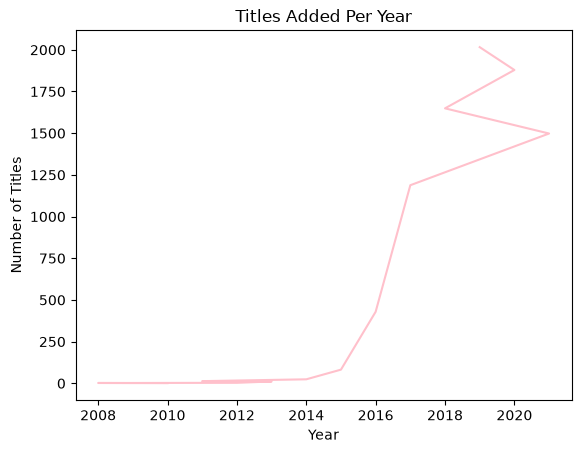

In [85]:
## Line Chart of Titles Added Per Year
plt.plot(df["date_added"].dt.year.value_counts(),color="pink")
plt.title("Titles Added Per Year")
plt.xlabel("Year")
plt.ylabel("Number of Titles")
plt.show()

# Netflix Movies & TV Shows Analysis – Business Report

## Project Overview

In this project, I analyzed the Netflix Movies and TV Shows dataset using Python, Pandas, NumPy, and Matplotlib. The goal of the analysis was to explore the dataset, clean the data, identify patterns, and gain insights into Netflix's content library.

---

## Data Cleaning

Before carrying out the analysis, the dataset was cleaned to improve its quality and reliability.

The following steps were performed:

- Replaced missing values in the **director**, **cast**, and **country** columns with **"Unknown"**.
- Replaced missing values in the **rating** column with **"Not Rated"**.
- Removed rows with missing values in the **date_added** column.
- Removed duplicate rows from the dataset.
- Converted the **date_added** column from text format to a datetime format for easier date analysis.

---

## Key Findings

Some of the major insights obtained from the analysis include:

- Movies are more common than TV Shows in the Netflix catalog.
- The **United States** has the highest number of Netflix titles.
- **2019** recorded the highest number of titles added to Netflix.
- **July** is the month with the highest number of titles added.
- **TV-MA** is the most common content rating.
- **Rajiv Chilaka** has the highest number of titles as a director.
- **Anupam Kher** is the actor with the highest number of appearances in the dataset.

---

## Visualizations

Several visualizations were created to better understand the dataset:

- **Bar Chart (Movies vs TV Shows):** Compared the number of Movies and TV Shows available on Netflix.
- **Horizontal Bar Chart (Top 10 Countries):** Showed the countries with the highest number of Netflix titles.
- **Bar Chart (Top 10 Directors):** Displayed the directors with the largest number of titles on Netflix.
- **Pie Chart (Movies vs TV Shows):** Illustrated the proportion of Movies and TV Shows in the Netflix catalog.
- **Line Chart (Titles Added Per Year):** Showed how the number of titles added to Netflix changed over the years.

---

## Conclusion

This analysis showed that Movies make up the majority of Netflix's content library, with the United States contributing the largest number of titles. The analysis also revealed that 2019 was the busiest year for content additions, while July recorded the highest number of titles added among all months. Overall, this project demonstrated how Python and Pandas can be used to clean data, perform exploratory data analysis, create visualizations, and communicate meaningful business insights.